# Exploración de los datos: hábitos de escucha musical por país (Last.fm, 2005–2014)

## Objetivo
Conocer la estructura de los datos de Last.fm, revisar su calidad y entender cómo se distribuyen las escuchas, los usuarios y las características musicales.

## Datos
- **Culture-Aware Music Recommendation Dataset** (Zangerle, Pichl y Schedl, 2020),
  un subconjunto del dataset LFM-1b de Last.fm. Fuente: https://zenodo.org/records/3477842
- **Nombres de artistas** del LFM-1b. Fuente: https://zenodo.org/record/3964506

Los archivos originales (.tsv) se convirtieron antes a formato parquet con el script
`00_convertir_a_parquet.py`.

## Herramientas
- **DuckDB**: para consultar los datos con SQL. Lo elegimos porque la tabla de escuchas
  tiene 351 millones de filas y no entra en memoria con pandas.
- **pandas**: para trabajar con los resultados de las consultas, que son tablas chicas.
- **matplotlib**: para los gráficos.

## Contenido

1. Importación de librerías y configuración
2. Descripción de los datos
3. Abstracción de los datos
4. Cobertura temporal y geográfica
5. Revisión de la calidad de los datos
6. Análisis exploratorio de las variables
7. Conclusiones

## 1. Preparación del entorno

In [35]:
# --- Librerías ---
import duckdb                    # motor SQL que lee archivos parquet sin cargarlos enteros en memoria
import pandas as pd              # para trabajar con los resultados como DataFrames
import matplotlib.pyplot as plt  # para graficar
from pathlib import Path        # para buscar carpetas

# --- Conexión a DuckDB ---
# connect() sin argumentos crea una base de datos en memoria (no se guarda ningún archivo).
# Solo la usamos para consultar los parquet.
con = duckdb.connect()

# Limitamos la memoria que puede usar DuckDB.
# Si una consulta necesita más, usa el disco en vez de trabar la computadora.
con.execute("SET memory_limit = '4GB'")

# El timestamp del dataset está en "unix time": segundos desde el 1/1/1970 en UTC (según el README).
# DuckDB muestra las fechas en la zona horaria de la computadora, salvo que se indique otra.
# Fijamos UTC para que las fechas no dependan de dónde se ejecute el notebook.
con.execute("SET TimeZone = 'UTC'")

# --- Vistas: un nombre corto para cada archivo ---
# Una vista no copia los datos: es como un "acceso directo" al archivo.
# Así en las consultas podemos escribir FROM users en vez de FROM 'data/parquet/users.parquet'.
# Buscamos la carpeta data subiendo desde la carpeta donde está el notebook.
# Así funciona esté en la raíz del repo o en una subcarpeta.
carpeta = Path.cwd()
while not (carpeta / "data" / "parquet").exists():
    if carpeta == carpeta.parent:
        raise FileNotFoundError("No encontramos la carpeta data/parquet. Revisar dónde está.")
    carpeta = carpeta.parent
ruta = (carpeta / "data" / "parquet").as_posix() + "/"

con.execute(f"CREATE OR REPLACE VIEW events            AS SELECT * FROM '{ruta}events.parquet'")
con.execute(f"CREATE OR REPLACE VIEW users             AS SELECT * FROM '{ruta}users.parquet'")
con.execute(f"CREATE OR REPLACE VIEW artists           AS SELECT * FROM '{ruta}artists.parquet'")
con.execute(f"CREATE OR REPLACE VIEW acoustic_features AS SELECT * FROM '{ruta}acoustic_features.parquet'")
con.execute(f"CREATE OR REPLACE VIEW hofstede          AS SELECT * FROM '{ruta}hofstede.parquet'")
con.execute(f"CREATE OR REPLACE VIEW happiness         AS SELECT * FROM '{ruta}happiness.parquet'")

# --- Función auxiliar ---
# Recibe una consulta SQL, la ejecuta y devuelve el resultado como DataFrame de pandas.
# La usamos para no repetir con.sql(...).df() en cada celda.
def q(consulta):
    return con.sql(consulta).df()

q("SELECT 'todo listo' AS estado")

,estado
0,todo listo


## 2. Conocer los datos

- **2.1** cuántas filas tiene cada tabla,
- **2.2** qué columnas tiene y de qué tipo es cada una,
- **2.3** cómo se ven las primeras filas.

### 2.1 Filas por tabla

In [36]:
# Lista con los nombres de las vistas creadas
tablas = ["events", "users", "artists", "acoustic_features", "hofstede", "happiness"]

# Para cada tabla contamos las filas con COUNT(*).
# fetchone()[0] devuelve directamente el número (en vez de una tabla de una sola celda).
for tabla in tablas:
    filas = con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    print(f"{tabla:20s} {filas:>15,} filas")   # :20s y :>15, solo alinean el texto y agregan separador de miles

events                   351,469,333 filas
users                         55,190 filas
artists                    3,190,371 filas
acoustic_features          3,471,884 filas
hofstede                          47 filas
happiness                      1,562 filas


### 2.2 Columnas de cada tabla

In [3]:
# DESCRIBE muestra cada columna de la tabla con su tipo de dato
# equivalente de df.info() en pandas.
# display() muestra cada resultado como tabla dentro del notebook.
for tabla in tablas:
    print(f"--- {tabla} ---")
    df_desc = con.execute(f"DESCRIBE {tabla}").df()
    display(df_desc[["column_name", "column_type"]])  # nos quedamos solo con nombre y tipo

--- events ---


,column_name,column_type
0,user_id,INTEGER
1,artist_id,INTEGER
2,album_id,INTEGER
3,track_id,INTEGER
4,timestamp,BIGINT


--- users ---


,column_name,column_type
0,user_id,BIGINT
1,country,VARCHAR
2,age,BIGINT
3,gender,VARCHAR
4,playcount,BIGINT
5,registered_unixtime,BIGINT


--- artists ---


,column_name,column_type
0,artist_id,INTEGER
1,artist_name,VARCHAR
2,gender_counts,VARCHAR


... (2 outputs left out)

--- hofstede ---


,column_name,column_type
0,no,BIGINT
1,ctr,VARCHAR
2,country,VARCHAR
3,power_distance,VARCHAR
4,individualism,VARCHAR
5,masculinity,VARCHAR
6,uncertainty_avoidance,VARCHAR
7,long_term_orientation,BIGINT
8,indulgence,VARCHAR


--- happiness ---


,column_name,column_type
0,country,VARCHAR
1,year,BIGINT
2,Life Ladder,DOUBLE
3,Log GDP per capita,DOUBLE
4,Social support,DOUBLE
5,Healthy life expectancy at birth,DOUBLE
6,Freedom to make life choices,DOUBLE
7,Generosity,DOUBLE
8,Perceptions of corruption,DOUBLE
9,Positive affect,DOUBLE


### 2.3 Primeras filas de cada tabla

In [4]:
# LIMIT 5 trae solo 5 filas
# Es el equivalente de df.head() en pandas.
for tabla in tablas:
    print(f"--- {tabla} ---")
    display(q(f"SELECT * FROM {tabla} LIMIT 5"))

--- events ---


,user_id,artist_id,album_id,track_id,timestamp
0,31435741,21,31,53,1370977938
1,31435741,21,31,53,1370977728
2,31435741,21,31,53,1370977518
3,31435741,21,31,53,1370977308
4,31435741,21,31,53,1370977098


--- users ---


,user_id,country,age,gender,playcount,registered_unixtime
0,384,UK,35,m,42139,1035849600
1,3653,UK,31,m,18504,1041033600
2,4813,US,43,m,640,1050364800
3,5069,AT,30,m,31867,1051488000
4,5213,UK,37,n,392,1052265600


--- artists ---


,artist_id,artist_name,gender_counts
0,1,Megadeth,4/20/0/0/0
1,2,Lil Wayne,0/1/0/0/0
2,3,Foo Fighters,0/8/0/0/0
3,4,Porcupine Tree,0/6/0/0/0
4,5,No-Man,1/3/0/0/0


... (2 outputs left out)

--- hofstede ---


,no,ctr,country,power_distance,individualism,masculinity,uncertainty_avoidance,long_term_orientation,indulgence
0,1,AR,Argentina,49,46,56,86,20,62
1,2,AT,Austria,11,55,79,70,60,63
2,3,AU,Australia,38,90,61,51,21,71
3,4,BE,Belgium,65,75,54,94,82,57
4,5,BG,Bulgeria,70,30,40,85,69,16


--- happiness ---


,country,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect,Confidence in national government,Democratic Quality,Delivery Quality,Standard deviation of ladder by country-year,Standard deviation/Mean of ladder by country-year,GINI index (World Bank estimate),"GINI index (World Bank estimate), average 2000-15","gini of household income reported in Gallup, by wp5-year"
0,Afghanistan,2008,3.723590,7.168690,0.450662,49.209663,0.718114,0.181819,0.881686,0.517637,0.258195,0.612072,-1.929690,-1.655084,1.774662,0.476600,NaN,NaN,NaN
1,Afghanistan,2009,4.401778,7.333790,0.552308,49.624432,0.678896,0.203614,0.850035,0.583926,0.237092,0.611545,-2.044093,-1.635025,1.722688,0.391362,NaN,NaN,0.441906
2,Afghanistan,2010,4.758381,7.386629,0.539075,50.008961,0.600127,0.137630,0.706766,0.618265,0.275324,0.299357,-1.991810,-1.617176,1.878622,0.394803,NaN,NaN,0.327318
3,Afghanistan,2011,3.831719,7.415019,0.521104,50.367298,0.495901,0.175329,0.731109,0.611387,0.267175,0.307386,-1.919018,-1.616221,1.785360,0.465942,NaN,NaN,0.336764
4,Afghanistan,2012,3.782938,7.517126,0.520637,50.709263,0.530935,0.247159,0.775620,0.710385,0.267919,0.435440,-1.842996,-1.404078,1.798283,0.475367,NaN,NaN,0.344540


## 3. Abstracción de datos

- ¿Qué entidades (ítems) estamos analizando?
- ¿Qué atributos las caracterizan y de qué tipo son?
- ¿Qué relaciones existen entre ellas?
- ¿Hay una estructura espacial asociada a los datos?

### 3.1 Ítems y estructura

| Tabla | Item | # Filas |
|---|---|---|
| `events` | una escucha: un usuario reprodujo una canción en un momento | 351.469.333 |
| `users` | un usuario de Last.fm | 55.190 |
| `artists` | un artista del LFM-1b completo | 3.190.371 |
| `acoustic_features` | una canción con sus descriptores de audio | 3.471.884 |
| `hofstede` | un país con sus dimensiones culturales | 47 |
| `happiness` | un país en un año de encuesta | 1.562 |


### 3.2 Relaciones entre las tablas

| Tabla | Se une con | Por |
|---|---|---|
| `events` | `users`, `artists`, `acoustic_features` | `user_id`, `artist_id`, `track_id` |
| `users` | `events`, `hofstede` | `user_id`, `country` (= `ctr` en `hofstede`) |
| `artists` | `events` | `artist_id` |
| `acoustic_features` | `events` | `track_id` |
| `hofstede` | `users` | `ctr` = `country` (código de 2 letras) |
| `happiness` | `users` | nombre del país en inglés (hay que convertirlo a código) |

`events` es la tabla de hechos: cada escucha apunta a un usuario, un artista y una canción.
Las demás tablas describen a cada uno de ellos (dimensiones).

```text
                         +-------------------+
                         |      artists      |
                         | artist_id         |
                         | artist_name       |
                         +-------------------+
                                   ^
                                   | artist_id
+-------------------+    +-------------------+    +-------------------+
| acoustic_features |    |      events       |    |       users       |
| track_id          |<---| user_id           |--->| user_id           |
| energy, valence,  |    | artist_id         |    | country           |
| danceability ...  |    | album_id          |    | age, gender       |
+-------------------+    | track_id          |    +-------------------+
          track_id       | timestamp         |         |          |
                         +-------------------+   country = ctr   nombre del país
                                                       |          |
                                                       v          v
                                              +------------+  +-------------+
                                              |  hofstede  |  |  happiness  |
                                              +------------+  +-------------+
```

### 3.3 Atributos y tipos

Clasificamos cada atributo con los tres tipos vistos en clase: categórico, ordinal y cuantitativo.

| Atributo | Tabla | Tipo | Comentario |
|---|---|---|---|
| `user_id`, `artist_id`, `album_id`, `track_id` | varias | Categórico |  |
| `timestamp`, `registered_unixtime` | `events`, `users` | Cuantitativo (tiempo) | Segundos desde 1970 en UTC (referencia horaria que permite representar fechas y horarios independientemente del país.) |
| `country`, `ctr` | `users`, `hofstede` | Categórico | Código de país de 2 letras |
| `country` | `hofstede`, `happiness` | Categórico | Nombre del país en inglés |
| `gender` | `users` | Categórico | "m", "f", "n" y vacío |
| `age` | `users` | Cuantitativo | Usa -1 cuando el usuario no la informó |
| `playcount` | `users` | Cuantitativo | El README avisa que no coincide con este dataset |
| `artist_name` | `artists` | Categórico | |
| `gender_counts` | `artists` | Categórico | Texto con cinco números separados por "/" (por ejemplo 4/20/0/0/0) |
| `danceability`, `energy`, `valence`, `acousticness`, `instrumentalness`, `speechiness`, `liveness` | `acoustic_features` | Cuantitativo | Entre 0 y 1 |
| `tempo` | `acoustic_features` | Cuantitativo | En BPM |
| `loudness` | `acoustic_features` | Cuantitativo | En dB (valores negativos) |
| `key` | `acoustic_features` | Categórico | Nota musical de 0 a 11, guardada como decimal |
| `mode` | `acoustic_features` | Categórico | 0 = menor, 1 = mayor, guardado como decimal |
| `power_distance`, `individualism`, `masculinity`, `uncertainty_avoidance`, `long_term_orientation`, `indulgence` | `hofstede` | Cuantitativo | Aprox. de 0 a 100. Cinco están guardadas como texto |
| `year` | `happiness` | Ordinal | Año de la encuesta|
| `Life Ladder` | `happiness` | Cuantitativo | Felicidad de 0 a 10 |
| `no` | `hofstede` | | Número de fila original|

Según el tipo de variable, se decide qué canal visual se puede usar después: un atributo categórico se
representa con tono, forma o posición; uno ordinal con posición, tamaño o intensidad; y uno
cuantitativo con posición, longitud, tamaño o intensidad.

## 4. Cobertura y período

Miramos cuántos artistas del catálogo aparecen en las escuchas, cómo se reparten los usuarios
por género y país, y qué período cubren las escuchas.

### 4.1 Cobertura de artistas y usuarios

In [37]:
# --- 1. Cobertura del catálogo de artistas ---
# Del total de escuchas, verificamos cuántos artistas distintos de la tabla artists aparecen en el dataset de eventos.
q("SELECT approx_count_distinct(artist_id) AS artistas_escuchados_aprox FROM events") #(approx_count_distinct da un valor aproximado, con un error de pocos puntos porcentuales.)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,artistas_escuchados_aprox
0,370549


La tabla `artists` tiene 3,19 millones de artistas del dataset LFM-1b original, pero solo
unos 370 mil aparecen en las escuchas. Esto pasa porque el dataset tiene solo las
canciones que se pudieron encontrar en Spotify para obtener sus audio features (según los
creadores del dataset, alrededor del 13% de las canciones). Por eso los datos representan sobre todo a
artistas conocidos.

In [6]:
# Qué valores toma cada columna de texto y cuántas veces aparece cada uno
# (equivalente a value_counts() de pandas)

# Género
display(q("SELECT gender, COUNT(*) AS usuarios FROM users GROUP BY gender ORDER BY usuarios DESC"))

# Países: cuántos hay en total y los 20 con más usuarios
display(q("SELECT COUNT(DISTINCT country) AS cantidad_paises FROM users"))
display(q("SELECT country, COUNT(*) AS usuarios FROM users GROUP BY country ORDER BY usuarios DESC LIMIT 20"))

,gender,usuarios
0,m,36506
1,f,13937
2,n,4663
3,,84


,cantidad_paises
0,208


,country,usuarios
0,US,10255
1,RU,5024
2,DE,4578
3,UK,4534
4,PL,4408
5,BR,3886
6,FI,1409
7,NL,1375
8,ES,1243
9,SE,1231


### 4.2 Período de las escuchas

In [7]:
# Primera y última escucha, convertidas de unix time a fecha legible
q("""
    SELECT to_timestamp(MIN("timestamp")) AS primera_escucha,
           to_timestamp(MAX("timestamp")) AS ultima_escucha
    FROM events
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,primera_escucha,ultima_escucha
0,1970-01-01 00:00:36+00:00,2014-09-01 23:56:08+00:00


In [8]:
# Cantidad de escuchas por año.
# year() saca el año de la fecha; así vemos si hay años "imposibles" (antes de 2005)
# y cuántas escuchas tienen.
por_anio = q("""
    SELECT year(to_timestamp("timestamp")) AS anio,
           COUNT(*) AS escuchas
    FROM events
    GROUP BY anio
    ORDER BY anio
""")
por_anio

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,escuchas
0,1970,1
1,2005,786963
2,2006,2870944
3,2007,7111575
4,2008,12657501
5,2009,21707665
6,2010,34585255
7,2011,55158881
8,2012,90705031
9,2013,91813023


## 5. Calidad de los datos

- **5.1** valores nulos,
- **5.2** valores faltantes "escondidos" y tipos de datos incorrectos,
- **5.3** valores fuera de rango y actividad anómala,
- **5.4** duplicados,
- **5.5** cruces entre tablas e inconsistencias de formato,
- **5.6** resumen de decisiones.

### 5.1 Valores nulos

In [ ]:
#5.1 valores nulos
# COUNT(*) cuenta todas las filas y COUNT(columna) solo las que no son nulas,
# así que la diferencia es la cantidad de nulos de esa columna.
def contar_nulos(tabla):
    columnas = q(f"DESCRIBE {tabla}")["column_name"]                        # lista de columnas de la tabla
    partes = [f'COUNT(*) - COUNT("{col}") AS "{col}"' for col in columnas]  # un conteo por columna
    resultado = q(f"SELECT {', '.join(partes)} FROM {tabla}").T             # .T: una fila por columna
    resultado.columns = ["nulos"]
    return resultado

for tabla in ["users", "artists","acoustic_features", "hofstede", "happiness"]:
    print(f"--- {tabla} ---")
    display(contar_nulos(tabla))

--- users ---


,nulos
user_id,0
country,0
age,0
gender,0
playcount,0
registered_unixtime,0


--- artists ---


,nulos
artist_id,0
artist_name,0
gender_counts,0


--- acoustic_features ---


,nulos
track_id,0
danceability,2655
energy,373
key,294
loudness,0
mode,294
speechiness,2654
acousticness,401
instrumentalness,454
liveness,759


--- hofstede ---


,nulos
no,0
ctr,0
country,0
power_distance,0
individualism,0
masculinity,0
uncertainty_avoidance,0
long_term_orientation,0
indulgence,0


--- happiness ---


,nulos
country,0
year,0
Life Ladder,0
Log GDP per capita,27
Social support,13
Healthy life expectancy at birth,9
Freedom to make life choices,29
Generosity,80
Perceptions of corruption,90
Positive affect,18


In [10]:
contar_nulos("events") #los eventos son millones

,nulos
user_id,0
artist_id,0
album_id,0
track_id,0
timestamp,0


**Observaciones 5.1**
- `events`, `users`, `artists` y `hofstede` no tienen valores nulos.
  - `acoustic_features` tiene pocos valores nulos. La variable con más nulos es `valence`, con 3.595 canciones. Según el README, la API de Spotify no devolvió todas las características de algunas canciones. Como representan una pequeña parte de los datos y `AVG()` calcula el promedio solo con los valores que no son nulos, decidimos mantenerlos.
- `happiness` tiene nulos en la mayoría de sus columnas, pero no en
  `Life Ladder`, que es la única que se va a usar.

### 5.2 Valores faltantes no identificados como nulos y tipos de datos incorrectos

In [38]:
# 5.2 Faltantes en users
# - País vacío: un texto '' no cuenta como nulo, pero tampoco es un país.
# - Género 'n': el README dice que solo puede ser 'm' o 'f', pero hay una n
# - Género con otro valor
q("""
    SELECT
        COUNT(*) FILTER (WHERE TRIM(country) = '')            AS pais_vacio,
        COUNT(*) FILTER (WHERE gender = 'n')                  AS genero_n,
        COUNT(*) FILTER (WHERE gender NOT IN ('m', 'f', 'n')) AS genero_otro_valor,
        COUNT(*)                                              AS total_usuarios
    FROM users
""")

,pais_vacio,genero_n,genero_otro_valor,total_usuarios
0,0,4663,84,55190


In [12]:
# Todos los valores de género y cuántos usuarios tiene cada uno
q("SELECT gender, COUNT(*) AS usuarios FROM users GROUP BY gender ORDER BY usuarios DESC")

,gender,usuarios
0,m,36506
1,f,13937
2,n,4663
3,,84


**Observaciones 5.2**
- Ningún usuario tiene el país vacío.
- En `gender` hay valores que no figuran en el README: 4.663 usuarios con n y 84 nulos.

### 5.3 Valores fuera de rango y registros de escucha inusuales

In [13]:
#5.3.a valores fuera de rango

# se consideran válidas las edades entre 10 y 90 años.
# Esta consulta muestra qué outliers aparecen y cuántos usuarios tiene cada uno.
q("""
    SELECT age, COUNT(*) AS usuarios
    FROM users
    WHERE age < 10 OR age > 90
    GROUP BY age
    ORDER BY usuarios DESC
""")

,age,usuarios
0,-1,12139
1,0,29
2,111,29
3,2,26
4,3,25
5,112,24
6,1,21
7,6,17
8,4,16
9,101,14


In [ ]:
#5.3.b audio features
# Un tempo de 0 BPM o un volumen de -60 dB (silencio total) no son posibles en una canción
# son valores que Spotify no pudo calcular y quedaron como 0 o como el mínimo de la escala.
q("""
    SELECT
        COUNT(*) FILTER (WHERE tempo = 0)      AS tempo_cero,
        COUNT(*) FILTER (WHERE loudness = -60) AS loudness_silencio,
        COUNT(*)                               AS total_canciones
    FROM acoustic_features
""")

,tempo_cero,loudness_silencio,total_canciones
0,2651,209,3471884


In [41]:
#5.3.c Fechas

# tabla por anio calculada en la exploracion de datos
# nos quedamos con los años fuera del período 2005-2014
fuera = por_anio[(por_anio["anio"] < 2005) | (por_anio["anio"] > 2014)]
fuera

,anio,escuchas
0,1970,1


In [ ]:
#5.3.d Valores atípicos

# Escuchas por usuario y por día.
# date_trunc('day', ) recorta la fecha al día (sin hora), para contar cuántas escuchas hubo cada día
# después nos quedamos con el máximo de cada usuario
por_usuario_dia = q("""
    SELECT user_id, MAX(escuchas_dia) AS max_escuchas_en_un_dia
    FROM (
        SELECT user_id,
               date_trunc('day', to_timestamp("timestamp")) AS dia,
               COUNT(*) AS escuchas_dia
        FROM events
        GROUP BY user_id, dia
    )
    GROUP BY user_id
""")

# describe() muestra mínimo, máximo, promedio y percentiles: así vemos si hay valores extremos
por_usuario_dia["max_escuchas_en_un_dia"].describe(percentiles=[0.5, 0.9, 0.99])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count    55143.000000
mean       102.233230
std         93.336707
min          1.000000
50%         85.000000
90%        185.000000
99%        399.000000
max       3534.000000
Name: max_escuchas_en_un_dia, dtype: float64

In [ ]:
# cuántos usuarios superan las 500 escuchas en un mismo día
(por_usuario_dia["max_escuchas_en_un_dia"] > 500).sum()

np.int64(307)

- La mitad de los usuarios tiene 85 escuchas o menos en su día de mayor actividad y el 99% está por debajo de las 399. Sin embargo, encontramos un máximo de 3.534 escuchas en un solo día, lo que equivale a una escucha cada 24 segundos durante todo el día.
- Con un primer límite de 500 escuchas diarias encontramos 307 usuarios. Para definir el límite final, tomamos como referencia cómo registra Last.fm las escuchas: una canción debe durar más de 30 segundos y reproducirse al menos la mitad de su duración o 4 minutos. Si tomamos canciones de aproximadamente 4 minutos, cada escucha requiere al menos 2 minutos. A partir de esto, establecimos un límite de 720 escuchas por día.

  Fuente: https://www.last.fm/api/scrobbling


In [ ]:
(por_usuario_dia["max_escuchas_en_un_dia"] > 720).sum()

np.int64(140)

In [42]:
# Cantidad de días por usuario que superan las 720 escuchas y total de escuchas en esos días
q("""
    SELECT COUNT(*)          AS dias_fuera_del_limite,
           SUM(escuchas_dia) AS escuchas_fuera_del_limite
    FROM (
        SELECT user_id,
               date_trunc('day', to_timestamp("timestamp")) AS dia,
               COUNT(*) AS escuchas_dia
        FROM events
        GROUP BY user_id, dia
    )
    WHERE escuchas_dia > 720
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,dias_fuera_del_limite,escuchas_en_dias_anomalos
0,664,727379.0


- Con el umbral de 720 quedan 140 usuarios, que acumulan 664 días anómalos con 727.379 escuchas
  (0,21% del total), un promedio de 1.095 escuchas por día. Decidimos eliminar las escuchas de
  esos días, pero no a los usuarios: el resto de su actividad es normal. La pérdida es mínima
  y evita que esos días distorsionen los análisis.

**Observaciones 5.3**
- **Edad:** 12.139 usuarios tienen edad -1, que en el dataset indica que no informaron su edad. También encontramos 157 usuarios menores de 10 años y 185 mayores de 90. En total, son 12.481 usuarios. Para el análisis vamos a considerar las edades entre 10 y 90 años.
- **Audio features:** 2.651 canciones tienen un tempo de 0 y 209 tienen un loudness de -60 dB. Es posible que Spotify no haya podido analizar correctamente estas canciones.

- **Fechas:** encontramos una sola escucha fuera del período

- **Escuchas por encima del límite:** 140 usuarios superan las 720 escuchas diarias. En total, encontramos 664 días por usuario que superan este límite y que representan 727.379 escuchas.

### 5.4 Duplicados

In [21]:
# 5.4 Duplicados
# COUNT(*) cuenta todas las filas; COUNT(DISTINCT ...) cuenta los IDs sin repetir.
# Si los dos números dan igual, no hay IDs duplicados.
q("""
    SELECT
        (SELECT COUNT(*) FROM users)                             AS filas_users,
        (SELECT COUNT(DISTINCT user_id) FROM users)              AS usuarios_distintos,
        (SELECT COUNT(*) FROM acoustic_features)                 AS filas_canciones,
        (SELECT COUNT(DISTINCT track_id) FROM acoustic_features) AS canciones_distintas,
        (SELECT COUNT(*) FROM artists)                           AS filas_artistas,
        (SELECT COUNT(DISTINCT artist_id) FROM artists)          AS artistas_distintos
""")

,filas_users,usuarios_distintos,filas_canciones,canciones_distintas,filas_artistas,artistas_distintos
0,55190,55190,3471884,3471884,3190371,3190371


In [22]:
# Escuchas duplicadas: mismo usuario, misma canción y mismo timestamp exacto.
# Agrupamos por esas tres columnas y contamos los grupos que aparecen más de una vez.
q("""
    SELECT COUNT(*) AS grupos_duplicados, SUM(veces - 1) AS filas_sobrantes
    FROM (
        SELECT user_id, track_id, "timestamp", COUNT(*) AS veces
        FROM events
        GROUP BY user_id, track_id, "timestamp"
        HAVING COUNT(*) > 1
    )
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grupos_duplicados,filas_sobrantes
0,0,NaN


**Observaciones 5.4**
- No hay IDs repetidos en `users`, `artists` ni `acoustic_features`.
- No hay escuchas duplicadas (mismo usuario, misma canción y mismo instante). Las repeticiones
  de una misma canción son escuchas reales en momentos distintos

### 5.5 Cruces entre tablas

Cruce sin pérdida de datos
- **5.5.a** que cada escucha encuentre su usuario, su artista y su canción;
- **5.5.b** cómo aparecen los países en `users`, `hofstede` y `happiness`, para ver si se pueden cruzar.

In [ ]:
#5.5.a escuchas sin usuario, artista o cancion

# LEFT JOIN conserva todas las escuchas, aunque no hagan match en la otra tabla.
# Si no la encuentran, las columnas de la otra tabla quedan en null.
# Contamos cuántas escuchas quedaron sin match en cada tabla.
q("""
    SELECT
        COUNT(*) FILTER (WHERE u.user_id   IS NULL) AS escuchas_sin_usuario,
        COUNT(*) FILTER (WHERE a.artist_id IS NULL) AS escuchas_sin_artista,
        COUNT(*) FILTER (WHERE f.track_id  IS NULL) AS escuchas_sin_audio_features
    FROM events e
    LEFT JOIN users u             ON e.user_id   = u.user_id
    LEFT JOIN artists a           ON e.artist_id = a.artist_id
    LEFT JOIN acoustic_features f ON e.track_id  = f.track_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,escuchas_sin_usuario,escuchas_sin_artista,escuchas_sin_audio_features
0,0,0,0


In [ ]:
# 5.5.b Cómo aparecen los países en users, hofstede y happiness

# 1. Lista 'users': conteo y lista completa de códigos de país
cant_users = q("SELECT COUNT(DISTINCT country) AS total FROM users WHERE TRIM(country) != ''")["total"][0]
paises_users = q("SELECT DISTINCT country FROM users WHERE TRIM(country) != '' ORDER BY country")["country"].tolist()
print(f"1. Tabla 'users': {cant_users} países distintos:")
print(paises_users)
print("-" * 80)

# 2. Tabla 'hofstede': conteo y tabla completa
df_hof_paises = q("SELECT DISTINCT ctr, country FROM hofstede ORDER BY country")
print(f"2. Tabla 'hofstede': {len(df_hof_paises)} países distintos:")
display(df_hof_paises)
print("-" * 80)

# 3. Lista 'happiness': conteo y lista completa de nombres de países
cant_hap = q("SELECT COUNT(DISTINCT country) AS total FROM happiness WHERE TRIM(country) != ''")["total"][0]
paises_hap = q("SELECT DISTINCT country FROM happiness WHERE TRIM(country) != '' ORDER BY country")["country"].tolist()
print(f"3. Tabla 'happiness': {cant_hap} países distintos:")
print(paises_hap)

1. Tabla 'users': 208 países distintos:
['AD', 'AE', 'AF', 'AL', 'AM', 'AO', 'AQ', 'AR', 'AS', 'AT', 'AU', 'AW', 'AZ', 'BA', 'BB', 'BD', 'BE', 'BF', 'BG', 'BI', 'BM', 'BN', 'BO', 'BR', 'BS', 'BT', 'BV', 'BW', 'BY', 'CA', 'CC', 'CD', 'CG', 'CH', 'CI', 'CK', 'CL', 'CN', 'CO', 'CR', 'CU', 'CV', 'CX', 'CY', 'CZ', 'DE', 'DJ', 'DK', 'DO', 'DZ', 'EC', 'EE', 'EG', 'EH', 'ES', 'ET', 'FI', 'FJ', 'FM', 'FO', 'FR', 'GA', 'GD', 'GE', 'GH', 'GI', 'GL', 'GN', 'GP', 'GR', 'GS', 'GT', 'GU', 'HK', 'HM', 'HN', 'HR', 'HT', 'HU', 'ID', 'IE', 'IL', 'IN', 'IO', 'IQ', 'IR', 'IS', 'IT', 'JM', 'JO', 'JP', 'KE', 'KG', 'KH', 'KI', 'KM', 'KN', 'KP', 'KR', 'KW', 'KY', 'KZ', 'LA', 'LB', 'LI', 'LK', 'LR', 'LS', 'LT', 'LU', 'LV', 'LY', 'MA', 'MD', 'ME', 'MG', 'MH', 'MK', 'MM', 'MN', 'MO', 'MP', 'MQ', 'MS', 'MT', 'MU', 'MV', 'MW', 'MX', 'MY', 'MZ', 'NA', 'NC', 'NE', 'NG', 'NI', 'NL', 'NO', 'NP', 'NR', 'NU', 'NZ', 'OM', 'PA', 'PE', 'PF', 'PG', 'PH', 'PK', 'PL', 'PM', 'PR', 'PS', 'PT', 'PW', 'PY', 'RE', 'RO', 'RS', 'RU',

,ctr,country
0,AR,Argentina
1,AU,Australia
2,AT,Austria
3,BY,Belarus
4,BE,Belgium
5,BR,Brazil
6,BG,Bulgeria
7,CA,Canada
8,CL,Chile
9,CN,China


--------------------------------------------------------------------------------
3. Tabla 'happiness': 164 países distintos:
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo (Brazzaville)', 'Congo (Kinshasa)', 'Costa Rica', 'Croatia', 'Cuba', 'Cyprus', 'Czech Republic', 'Denmark', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Finland', 'France', 'Gabon', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'Hong Kong S.A.R. of China', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Ja

**Observaciones 5.5**
- Todas las escuchas encuentran su usuario, su artista y su canción por lo que las tablas se pueden unir
  sin perder datos.
- Cada tabla identifica los países de forma distinta:
  - `users` usa códigos de 2 letras (208 países).
  - `hofstede` tiene el código (`ctr`) y el nombre (47 países). Usa el mismo código que `users`,
    incluso "UK" para el Reino Unido, así que se unen directamente.
  - `happiness` solo tiene el nombre en inglés y una fila por país y año (164 países).
- El Reino Unido figura como "UK" en `users` y `hofstede`, pero el código estándar es "GB"
  (en `happiness` aparece como "United Kingdom").
- En `hofstede` hay nombres mal escritos o abreviados ("Bulgeria", "U.S.A.", "Czech Rep",
  "Slovak Rep"), y en `happiness` nombres largos como "Taiwan Province of China" o
  "Congo (Kinshasa)". Por eso no conviene unir por nombre.
- Los 47 países de `hofstede` concentran 53.309 de los 55.190 usuarios.
- Para cruzar `happiness` con `users` hay que quedarse con los años 2005–2014 (el período de las
  escuchas) y convertir cada nombre a su código de 2 letras, por ejemplo con la librería
  `pycountry` y una lista de excepciones para los nombres que no reconozca.

### 5.6 Resumen

| Problema | Tamaño | Operación | Decisión | Justificación |
|---|---|---|---|---|
| Nulos en audio features | Máx. 3.595 canciones | |  | Son muy pocos y los promedios los ignoran |
| Nulos en `happiness` | Varias columnas | Selección de atributos | Usar solo `Life Ladder`, que no tiene nulos | Las demás columnas no se usan |
| Edad -1 o fuera de 10–90 | 12.481 usuarios | Limpieza | Pasar a nulo | No son edades reales |
| Género "n" o vacío | 4.747 usuarios | Limpieza | Agrupar como "no informado" | Valores no documentados |
| Dimensiones de Hofstede como texto | 5 columnas | Limpieza | Convertir a número | Tipo de dato incorrecto |
| Tempo 0 | 2.651 canciones | Limpieza | Pasar a nulo | Valor imposible |
| Loudness -60 dB | 209 canciones | Limpieza | Pasar a nulo | Valor imposible |
| Escucha con fecha 1970 | 1 escucha | Filtrado | Eliminar | Fecha imposible |
| Días con más de 720 escuchas | 664 días, 727.379 escuchas  | Filtrado | Eliminar las escuchas de esos días | Imposibles según Last.fm |
| Usuarios sin escuchas | 47 | | Nada | No aparecen en los análisis |
| Duplicados | 0 | | Nada | No hay |
| Escuchas sin pareja en otras tablas | 0 | | Nada | Todo cruza |
| "UK" en `users` y `hofstede` | 4.534 usuarios | Limpieza | Cambiar a "GB" | Es el código estándar |
| Nombres mal escritos o abreviados en `hofstede` | 5 países | Limpieza | Corregir | |
| `happiness` sin código de país y con años posteriores al período | 164 países | Limpieza y filtrado | Convertir el nombre a código y quedarse con 2005–2014 | Poder unir con `users` y usar el mismo período que las escuchas |
| Atributos que no se usan: `album_id`, `playcount`, `registered_unixtime` | | Selección de atributos | Sacarlos de las tablas limpias | No se usan |

Los usuarios con edad o género faltante no se eliminan, solo quedan fuera de los análisis que
usan esas variables, porque sus escuchas sirven para todo lo demás.

## 6. Análisis de las variables

Describimos cada variable por separado, cómo se distribuye, cuáles son sus valores típicos y si
tiene sesgos o valores extremos.

### 6.1 Usuarios

count    42709.000000
mean        25.109345
std          7.984870
min         10.000000
25%         20.000000
50%         23.000000
75%         28.000000
max         90.000000
Name: age, dtype: float64


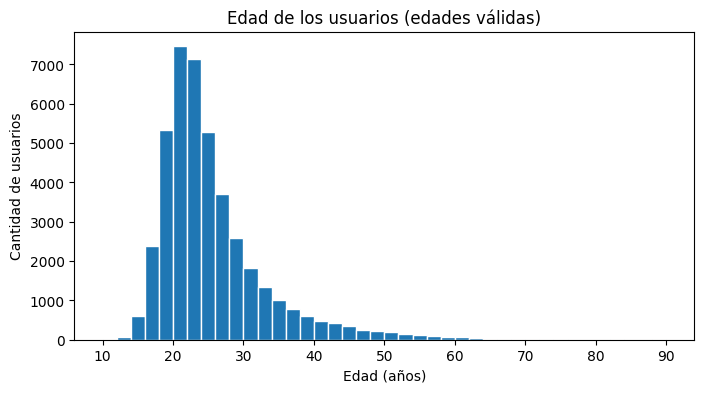

In [ ]:
# 6.1.a Edad: solo edades válidas (entre 10 y 90)
edades = q("SELECT age FROM users WHERE age BETWEEN 10 AND 90")
print(edades["age"].describe())

plt.figure(figsize=(8, 4))
plt.hist(edades["age"], bins=range(10, 92, 2), edgecolor="white")
plt.title("Edad de los usuarios (edades válidas)")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 6.1.a (edad):** la mitad de los usuarios tiene entre 20 y 28 años, con una mediana
de 23.

,genero,usuarios,porcentaje
0,m,36506,66.1
1,f,13937,25.3
2,no informado,4747,8.6


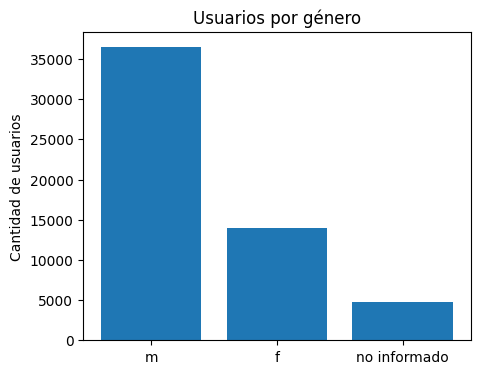

In [ ]:
# 6.1.b Género: agrupamos "n" y los vacíos como "no informado" 
genero = q("""
    SELECT CASE WHEN gender IN ('m', 'f') THEN gender ELSE 'no informado' END AS genero,
           COUNT(*) AS usuarios
    FROM users
    GROUP BY genero
    ORDER BY usuarios DESC
""")
genero["porcentaje"] = (genero["usuarios"] / genero["usuarios"].sum() * 100).round(1)
display(genero)

plt.figure(figsize=(5, 4))
plt.bar(genero["genero"], genero["usuarios"])
plt.title("Usuarios por género")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 6.1.b (género):** el 66% de los usuarios son hombres, el 25% mujeres y el 8,6%
no informó su género. La muestra está sesgada hacia usuarios hombres.

Cantidad de países: 208
Los 10 países con más usuarios suman el 68.7 % de los usuarios
Países con menos de 50 usuarios: 152


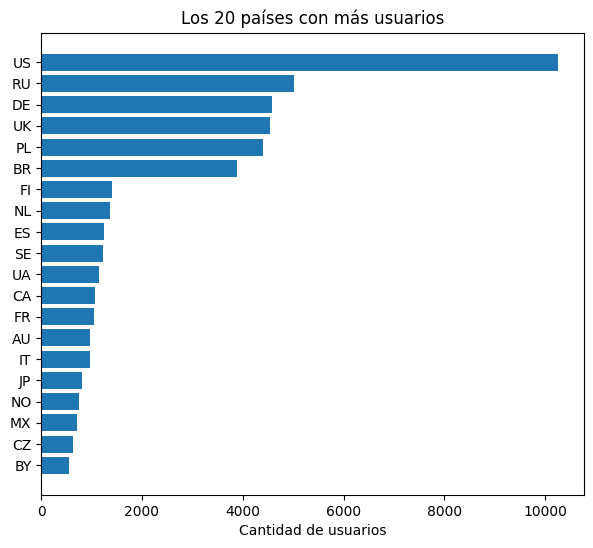

In [27]:
# 6.1.c País
paises = q("SELECT country, COUNT(*) AS usuarios FROM users GROUP BY country ORDER BY usuarios DESC")

# Porcentaje acumulado: qué parte del total suman los primeros países de la lista
paises["pct_acumulado"] = (paises["usuarios"].cumsum() / paises["usuarios"].sum() * 100).round(1)

print("Cantidad de países:", len(paises))
print("Los 10 países con más usuarios suman el", paises["pct_acumulado"].iloc[9], "% de los usuarios")
print("Países con menos de 50 usuarios:", (paises["usuarios"] < 50).sum())

# Los 20 primeros; iloc[::-1] invierte el orden para que el mayor quede arriba
top20 = paises.head(20).iloc[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top20["country"], top20["usuarios"])
plt.title("Los 20 países con más usuarios")
plt.xlabel("Cantidad de usuarios")
plt.show()

In [ ]:
# 6.1.d Cuántos países quedan según el mínimo de usuarios que pidamos

for minimo in [10, 30, 50, 100]:
    quedan = paises[paises["usuarios"] >= minimo]
    pct = quedan["usuarios"].sum() / paises["usuarios"].sum() * 100
    print(f"Mínimo {minimo:>3} usuarios: {len(quedan):>3} países, que reúnen el {pct:.1f}% de los usuarios")

Mínimo  10 usuarios:  98 países, que reúnen el 99.3% de los usuarios
Mínimo  30 usuarios:  68 países, que reúnen el 98.5% de los usuarios
Mínimo  50 usuarios:  56 países, que reúnen el 97.7% de los usuarios
Mínimo 100 usuarios:  47 países, que reúnen el 96.6% de los usuarios


**Observación 6.1.d (mínimo de usuarios por país):** al aumentar el mínimo de usuarios, quedan menos países, pero se sigue manteniendo un alto porcentaje del total de usuarios.

### 6.2 Escuchas

count     55143.000000
mean       6373.779682
std        9118.109300
min           1.000000
25%        1242.000000
50%        5028.000000
75%        8750.000000
max      345014.000000
Name: escuchas, dtype: float64


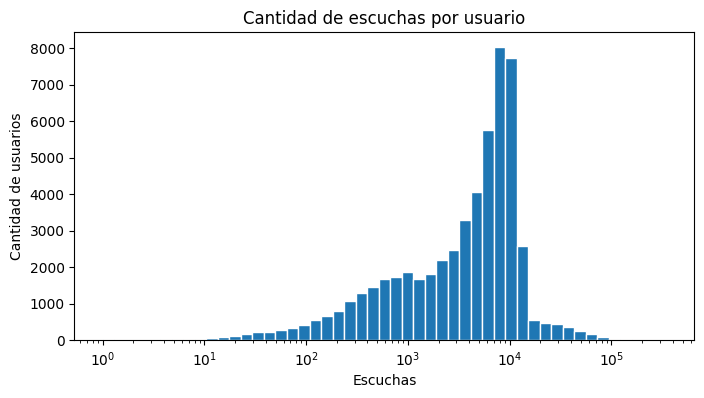

In [29]:
# 6.2.a Escuchas por usuario
import numpy as np

por_usuario = q("SELECT user_id, COUNT(*) AS escuchas FROM events GROUP BY user_id")
print(por_usuario["escuchas"].describe())

# Los valores van de 1 a cientos de miles: con escala lineal todo queda amontonado a la izquierda.
# Usamos intervalos y eje en escala logarítmica para poder ver la distribución.
intervalos = np.logspace(0, np.log10(por_usuario["escuchas"].max()), 50)

plt.figure(figsize=(8, 4))
plt.hist(por_usuario["escuchas"], bins=intervalos, edgecolor="white")
plt.xscale("log")
plt.title("Cantidad de escuchas por usuario")
plt.xlabel("Escuchas")
plt.ylabel("Cantidad de usuarios")
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,escuchas,usuarios_activos,escuchas_por_usuario
0,2005,786963,606,1299.0
1,2006,2870944,1888,1521.0
2,2007,7111575,4282,1661.0
3,2008,12657501,7805,1622.0
4,2009,21707665,13242,1639.0
5,2010,34585255,20708,1670.0
6,2011,55158881,33163,1663.0
7,2012,90705031,50545,1795.0
8,2013,91813023,44816,2049.0
9,2014,34072494,34792,979.0


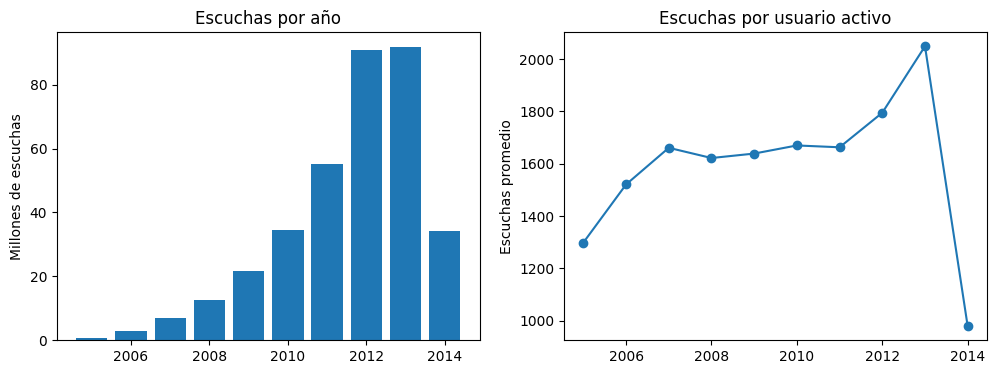

In [ ]:
# 6.2.b Escuchas por año, y escuchas promedio por usuario activo en cada año
#usuario activo: registró al menos una escucha durante el período analizado.
anual = q("""
    SELECT year(to_timestamp("timestamp")) AS anio,
           COUNT(*)                AS escuchas,
           COUNT(DISTINCT user_id) AS usuarios_activos
    FROM events
    WHERE "timestamp" >= 1104537600
    GROUP BY anio
    ORDER BY anio
""")
anual["escuchas_por_usuario"] = (anual["escuchas"] / anual["usuarios_activos"]).round()
display(anual)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(anual["anio"], anual["escuchas"] / 1e6)
ejes[0].set_title("Escuchas por año")
ejes[0].set_ylabel("Millones de escuchas")
ejes[1].plot(anual["anio"], anual["escuchas_por_usuario"], marker="o")
ejes[1].set_title("Escuchas por usuario activo")
ejes[1].set_ylabel("Escuchas promedio")
plt.show()

**Observación 6.2.b (escuchas por año):**

- Si bien las escuchas totales por año aumentan, la cantidad de escuchas por usuario activo se mantiene bastante estable con un aumento en 2012 y 2013.
- El aumento de las escuchas totales puede deberse a que cada año hay más usuarios activos, y no tanto a que cada usuario escuche más música. Incluso puede que haya mas usuarios registrados en Lastfm.
- 2014: las escuchas disminuyen porque los datos solo llegan hasta agosto.
- En 2005 y 2006 hay muy pocos usuarios activos, así que lo que veamos en esos años se apoya en pocos usuarios.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

El 1% de artistas más escuchados (3,378 artistas) suma el 69.2% de las escuchas
El 10% de artistas más escuchados (33,784 artistas) suma el 96.3% de las escuchas


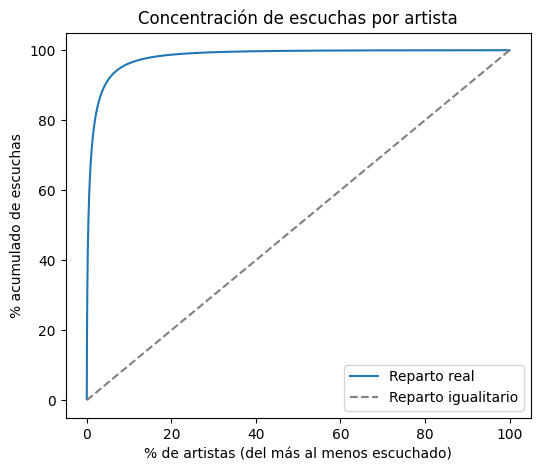

In [31]:
# 6.2.c Concentración de escuchas por artista
por_artista = q("SELECT artist_id, COUNT(*) AS escuchas FROM events GROUP BY artist_id ORDER BY escuchas DESC")

# Porcentaje acumulado de escuchas y de artistas, del más al menos escuchado
por_artista["pct_escuchas"] = por_artista["escuchas"].cumsum() / por_artista["escuchas"].sum() * 100
por_artista["pct_artistas"] = np.arange(1, len(por_artista) + 1) / len(por_artista) * 100

for p in [1, 10]:
    n = int(len(por_artista) * p / 100)
    print(f"El {p}% de artistas más escuchados ({n:,} artistas) suma el "
          f"{por_artista['pct_escuchas'].iloc[n - 1]:.1f}% de las escuchas")

plt.figure(figsize=(6, 5))
plt.plot(por_artista["pct_artistas"], por_artista["pct_escuchas"], label="Reparto real")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Reparto igualitario")
plt.title("Concentración de escuchas por artista")
plt.xlabel("% de artistas (del más al menos escuchado)")
plt.ylabel("% acumulado de escuchas")
plt.legend()
plt.show()

**Observación 6.2.c (concentración por artista):** Las escuchas están muy concentradas en un grupo reducido de artistas. Apenas el 1% de los artistas reúne el 69,2% de las reproducciones, mientras que el 10% concentra el 96,3%.

### 6.3 Audio features

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,loudness,tempo
count,200000.000,200000.000,199940.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000
mean,0.518,0.611,0.457,0.320,0.273,0.085,0.207,-9.704,121.435
std,0.182,0.271,0.267,0.354,0.368,0.114,0.180,5.335,29.488
min,0.000,0.000,0.000,0.000,0.000,0.022,0.005,-55.661,30.866
25%,0.389,0.406,0.230,0.006,0.000,0.035,0.097,-12.121,98.952
50%,0.526,0.652,0.442,0.142,0.008,0.047,0.130,-8.428,120.547
75%,0.654,0.850,0.672,0.650,0.677,0.080,0.268,-5.959,139.837
max,0.995,1.000,1.000,0.996,1.000,0.968,1.000,5.276,247.995


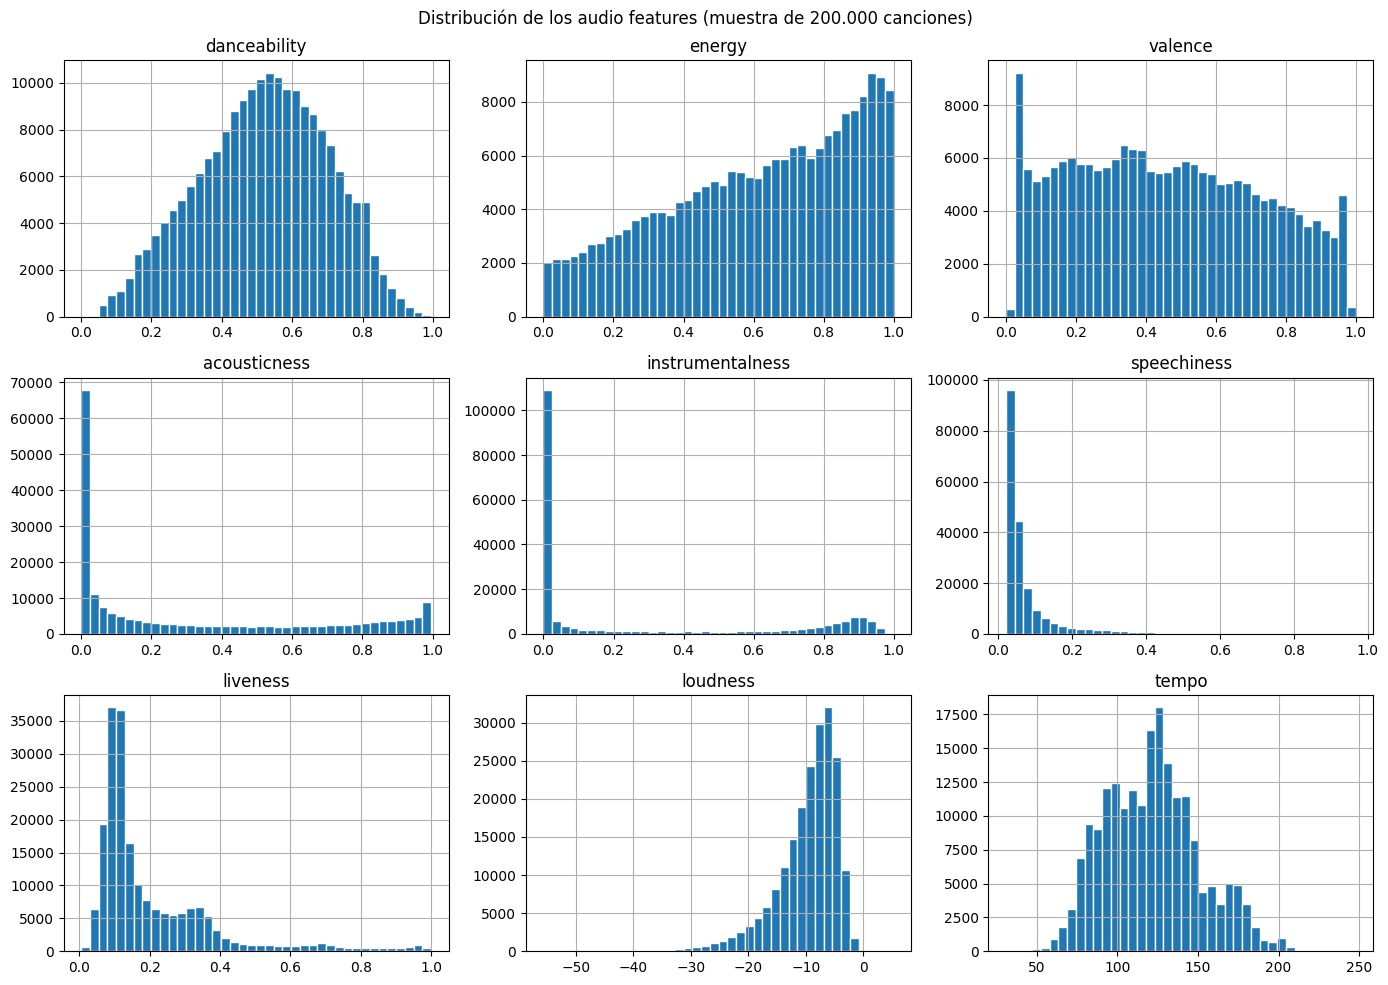

In [ ]:
# 6.3.a Distribución de cada audio feature
features = ["danceability", "energy", "valence", "acousticness", "instrumentalness",
            "speechiness", "liveness", "loudness", "tempo"]

muestra = q(f"""
    SELECT * FROM (
        SELECT {', '.join(features)}
        FROM acoustic_features
        WHERE tempo > 0 AND loudness > -60
    ) USING SAMPLE 200000 ROWS
""")

display(muestra.describe().round(3))

muestra.hist(bins=40, figsize=(14, 10), edgecolor="white")
plt.suptitle("Distribución de los audio features (muestra de 200.000 canciones)")
plt.tight_layout()
plt.show()

**Observación 6.3.a (distribuciones):** 

Danceability: La mayoría de las canciones se concentra alrededor de 0,55, con una distribución bastante similar a una campana.

Energy: Predominan los valores altos

Valence: Los valores están bastante distribuidos a lo largo de la escala, aunque se observan algunas concentraciones cerca de los extremos

Acousticness: La mayoría de las canciones presenta valores cercanos a 0, mientras que hay un grupo más reducido con valores próximos a 1.

Instrumentalness: La mayor parte de las canciones tiene valores cercanos a 0, mientras que un grupo menor presenta valores altos

Speechiness: Los valores se concentran por debajo de 0,1, por lo que hay poca variación en esta característica.

Liveness: La mayoría de las canciones presenta valores bajos, con una concentración alrededor de 0,1.

Loudness: la mitad de las canciones está entre -12 y -6 dB, con una mediana de -8,4 dB.

Tempo: la mediana es de unos 121 BPM y la mayoría está entre 99 y 140 BPM.

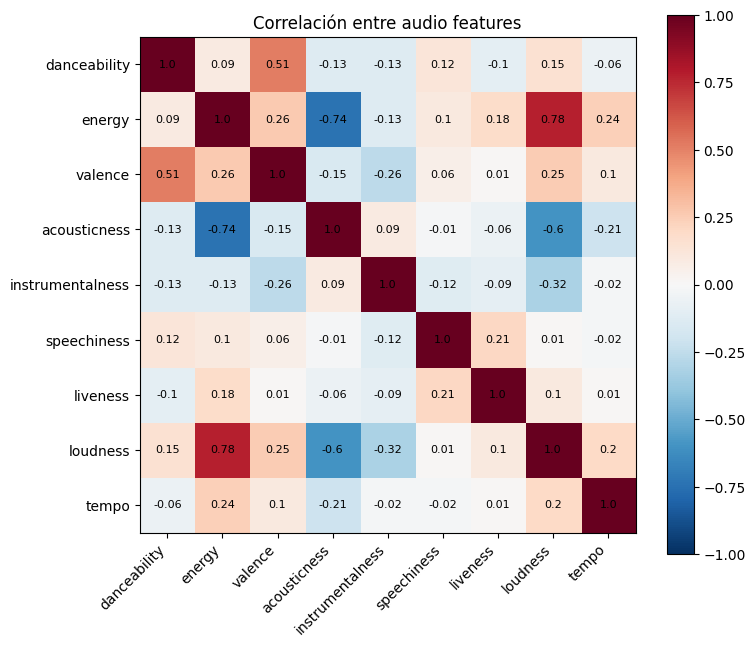

In [33]:
# 6.3.b Correlación entre audio features
corr = muestra.corr().round(2)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im)
plt.title("Correlación entre audio features")
plt.show()

**Observación 6.3.b (correlación):** 

-energy y loudness: 0,78. Las canciones enérgicas suelen ser fuertes.\
-energy y acousticness: -0,74. Las acústicas suelen ser tranquilas.\
-acousticness y loudness: -0,60.\
-danceability y valence: 0,51. Lo bailable suele sonar alegre.\
-El resto, cerca de 0.

## 7. Resumen General

- Solo unos 370 mil artistas aparecen en las escuchas.
- Los usuarios son de 208 países, muy concentrados: Estados Unidos (10.255), Rusia (5.024)
  y Alemania (4.578) son los que más tienen. Argentina tiene 282.
- En género, además de "m" (36.506) y "f" (13.937), aparecen "n" (4.663) y 84 valores vacíos.
- El período declarado es enero 2005 – agosto 2014, pero la primera escucha tiene fecha
  01/01/1970: es un timestamp inválido. La cantidad de escuchas crece mucho con los años. 2014 tiene menos porque llega hasta agosto.
- Un mismo usuario puede escuchar la misma canción muchas veces seguidas.
- `key` y `mode` están guardados como decimales, pero son categóricas.
- En `hofstede`, el código de país coincide con el de `users`. Hay un error de tipeo ("Bulgeria")
  y varias dimensiones están guardadas como texto en lugar de números.
- En `happiness`, no todos los países tienen datos desde el mismo año